# CONSORT Flow Diagram

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Scientific:* Specialised plots for statistics and scientific research: survival, effect sizes, agreement, omics, study flow and longitudinal data.

## Design purpose

A standardised flowchart showing how participants moved through a randomised trial, from assessment for eligibility through allocation and follow-up to analysis, with the number excluded and the reason at each step. Readers use it to judge selection bias and attrition.

## When to use

- Report any randomised controlled trial (required by the CONSORT statement and most journals)
- Show participant flow in cohort studies or screening programmes (STROBE/STARD-style flow)
- Make attrition and exclusions transparent

## Avoid when

- The process is not a sequential flow of participants (use a Sankey diagram for many-to-many flows)

## Alternatives

- Sankey diagram (when flows split and merge)
- Funnel chart (single-path attrition)

## Design tips

- Make the numbers add up at every step; reviewers check them
- Keep arms side by side with identical box positions so they can be compared
- Put exclusion reasons in side boxes, not in the main flow

## Example

A synthetic two-arm trial with 480 people assessed, 360 randomised, and loss to follow-up in each arm.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.patches import FancyBboxPatch

### Data

In [2]:
flow = {
    "assessed": 480,
    "excluded": {"Not meeting inclusion criteria": 72, "Declined to participate": 38, "Other reasons": 10},
    "arms": {
        "Intervention": {"allocated": 181, "received": 176, "not_received": 5,
                         "lost": {"Lost to follow-up": 7, "Discontinued (adverse events)": 4}, "analysed": 181},
        "Control": {"allocated": 179, "received": 179, "not_received": 0,
                    "lost": {"Lost to follow-up": 9, "Discontinued (withdrew consent)": 3}, "analysed": 179},
    },
}
randomised = flow["assessed"] - sum(flow["excluded"].values())
assert randomised == sum(a["allocated"] for a in flow["arms"].values())
print("randomised:", randomised)

randomised: 360


### Plot

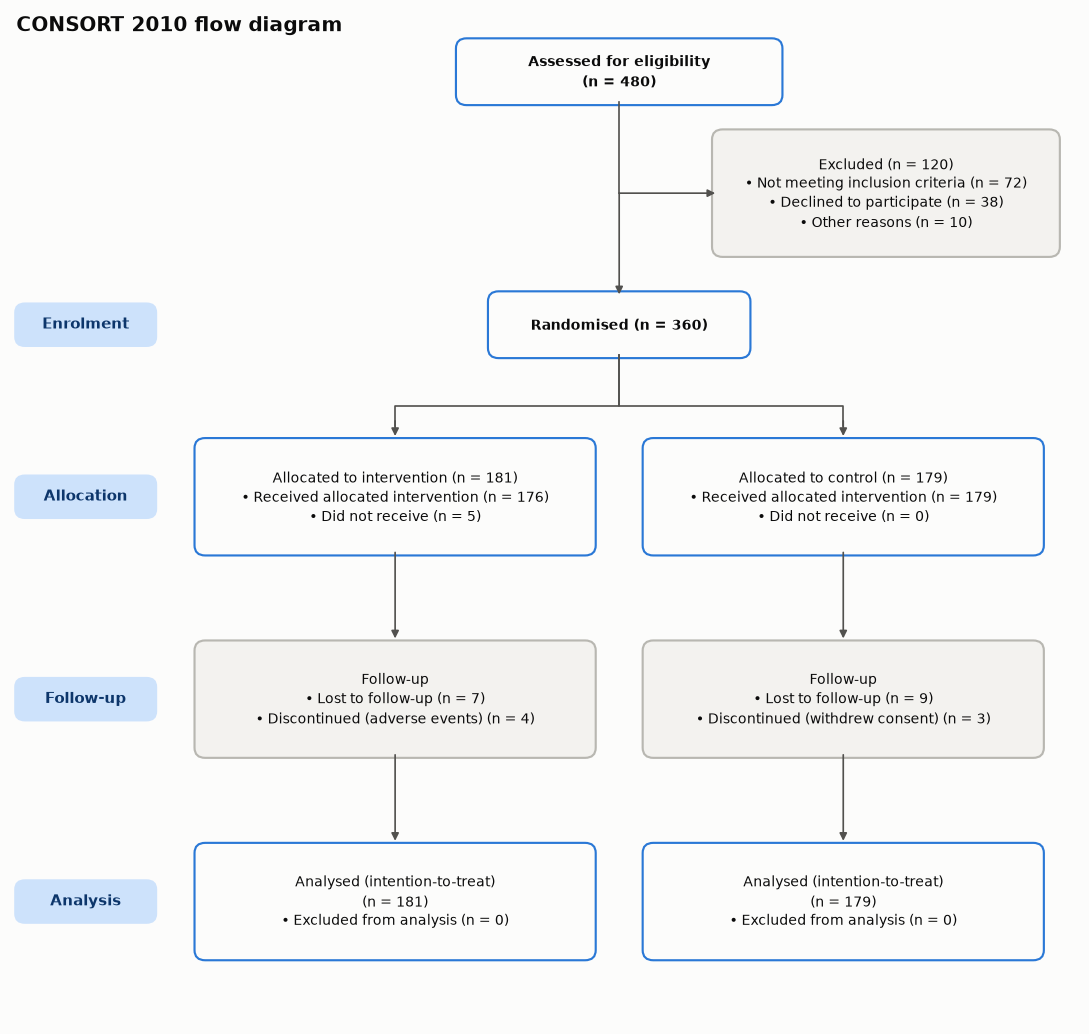

In [3]:
fig, ax = plt.subplots(figsize=(10, 9.5))
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")
ax.grid(False)

def box(x, y, w, h, text, main=True, bold=False):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.3,rounding_size=1",
                                facecolor="#fcfcfb" if main else "#f3f2ef",
                                edgecolor=PALETTE[0] if main else "#b8b7b1", linewidth=1.4))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, color="#0b0b0b",
            fontweight="bold" if bold else "normal", linespacing=1.4)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="#52514e", linewidth=1.1, shrinkA=0, shrinkB=0))

def stage(y, label):
    ax.add_patch(FancyBboxPatch((0.5, y - 2), 13, 4, boxstyle="round,pad=0.2,rounding_size=1",
                                facecolor="#cde2fb", edgecolor="none"))
    ax.text(7, y, label, ha="center", va="center", fontsize=9.5, fontweight="bold", color="#0d366b")

box(57, 94, 30, 6, f"Assessed for eligibility\n(n = {flow['assessed']})", bold=True)
excl = "\n".join(f"• {k} (n = {v})" for k, v in flow["excluded"].items())
box(82, 82, 32, 12, f"Excluded (n = {sum(flow['excluded'].values())})\n{excl}", main=False)
ax.plot([57, 57], [91, 82], color="#52514e", linewidth=1.1)
arrow(57, 82, 66, 82)
arrow(57, 82, 57, 72)
box(57, 69, 24, 6, f"Randomised (n = {randomised})", bold=True)
stage(69, "Enrolment")
for x, (arm, a) in zip([36, 78], flow["arms"].items()):
    ax.plot([57, 57, x, x], [66, 61, 61, 59], color="#52514e", linewidth=1.1)
    arrow(x, 59.5, x, 58)
    nr = f"\n• Did not receive (n = {a['not_received']})" if a["not_received"] else "\n• Did not receive (n = 0)"
    box(x, 52, 37, 11, f"Allocated to {arm.lower()} (n = {a['allocated']})\n"
                       f"• Received allocated intervention (n = {a['received']}){nr}")
    lost = "\n".join(f"• {k} (n = {v})" for k, v in a["lost"].items())
    arrow(x, 46.5, x, 38)
    box(x, 32, 37, 11, f"Follow-up\n{lost}", main=False)
    arrow(x, 26.5, x, 18)
    box(x, 12, 37, 11, f"Analysed (intention-to-treat)\n(n = {a['analysed']})\n• Excluded from analysis (n = 0)")
stage(52, "Allocation")
stage(32, "Follow-up")
stage(12, "Analysis")
ax.text(0.5, 99.5, "CONSORT 2010 flow diagram", fontsize=13, fontweight="bold", va="top")
fig.tight_layout()
plt.show()

## How to read it

Follow the main flow from top to bottom. Side boxes give the people excluded at each stage and why. Compare the arms row by row to see whether attrition differs between them.

---
Standalone script: [`consort_diagram.py`](consort_diagram.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)